# Electric Vehicle Analysis

This notebook explores electric vehicle adoption across European countries.

The analysis focuses on identifying adoption trends, comparing countries and investigating relationships between EV adoption, charging infrastructure and economic indicators.

In [2]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
ev_data = pd.read_csv("../data/cleaned/electric_vehicle_data.csv")

ev_data.head()

,country,country_code,year,bev_registrations,avg_monthly_bev_share_pct,months_available,charging_points,gdp_per_capita,population,electricity_price,electricity_periods,bev_registrations_per_1000_people
0,Albania,ALB,2019,24.0,0.063333,12,NaN,4850.0,2862427.0,0.09265,2.0,0.008384
1,Albania,ALB,2020,239.0,0.573333,12,NaN,4710.0,2845955.0,0.09210,2.0,0.083979
2,Albania,ALB,2021,262.0,0.477500,12,NaN,5190.0,2829741.0,0.09310,2.0,0.092588
3,Albania,ALB,2022,624.0,1.251667,12,NaN,5500.0,2793592.0,0.09585,2.0,0.223368
4,Albania,ALB,2023,1671.0,2.505833,12,NaN,NaN,2761785.0,0.10495,2.0,0.605043


## Selecting the Analysis Period

For the main analysis, we focus on 2015–2025.

- This period allows us to explore more recent EV adoption trends.
- We keep the original dataset unchanged and create a separate dataset for analysis.

In [5]:
ev_analysis = ev_data[ev_data["year"].between(2015, 2025)].copy()

In [6]:
print("Shape:", ev_analysis.shape)
print("Countries:", ev_analysis["country"].nunique())
print("Year range:", ev_analysis["year"].min(), "-", ev_analysis["year"].max())

ev_analysis.head()

Shape: (232, 12)
Countries: 33
Year range: 2015 - 2025


,country,country_code,year,bev_registrations,avg_monthly_bev_share_pct,months_available,charging_points,gdp_per_capita,population,electricity_price,electricity_periods,bev_registrations_per_1000_people
0,Albania,ALB,2019,24.0,0.063333,12,NaN,4850.0,2862427.0,0.09265,2.0,0.008384
1,Albania,ALB,2020,239.0,0.573333,12,NaN,4710.0,2845955.0,0.09210,2.0,0.083979
2,Albania,ALB,2021,262.0,0.477500,12,NaN,5190.0,2829741.0,0.09310,2.0,0.092588
3,Albania,ALB,2022,624.0,1.251667,12,NaN,5500.0,2793592.0,0.09585,2.0,0.223368
4,Albania,ALB,2023,1671.0,2.505833,12,NaN,NaN,2761785.0,0.10495,2.0,0.605043


## Exploratory Data Analysis (EDA)

### Summary Statistics

We begin by examining the main numerical variables using descriptive statistics such as the mean, median, minimum and maximum.

In [7]:
ev_analysis.describe()

,year,bev_registrations,avg_monthly_bev_share_pct,months_available,charging_points,gdp_per_capita,population,electricity_price,electricity_periods,bev_registrations_per_1000_people
count,232.000000,232.000000,232.000000,232.000000,118.000000,210.000000,2.280000e+02,211.000000,211.000000,228.000000
mean,2021.120690,47719.646552,12.047896,11.978448,29078.319314,43388.238095,2.084842e+07,0.220835,1.990521,3.225847
std,3.037016,91648.269808,15.675425,0.328266,44108.131711,24274.907797,2.433815e+07,0.077335,0.097126,4.984677
min,2015.000000,24.000000,0.063333,7.000000,84.000000,4710.000000,3.835670e+05,0.028450,1.000000,0.008384
25%,2019.000000,2497.750000,1.746667,12.000000,3021.000000,22070.000000,5.363605e+06,0.175825,2.000000,0.384453
50%,2022.000000,10968.000000,6.271667,12.000000,9248.490500,42695.000000,9.799186e+06,0.218500,2.000000,1.104300
75%,2024.000000,46628.750000,17.567917,12.000000,33107.000000,54452.500000,3.693566e+07,0.264250,2.000000,4.264326
max,2025.000000,545142.000000,95.586667,12.000000,209513.000000,107570.000000,8.357714e+07,0.521500,2.000000,30.786473


In [8]:
missing_values = ev_analysis.isna().sum()

missing_values[missing_values > 0]

charging_points                      114
gdp_per_capita                        22
population                             4
electricity_price                     21
electricity_periods                   21
bev_registrations_per_1000_people      4
dtype: int64

In [9]:
# Calculate the number of missing values in each column
missing_count = ev_analysis.isna().sum()

# Calculate the percentage of missing values in each column
missing_percentage = (missing_count / len(ev_analysis)) * 100

# Combine both results into a summary table
missing_summary = pd.DataFrame(
    {"missing_count": missing_count, "missing_percentage": missing_percentage}
)

# Display only columns that contain missing values
missing_summary = missing_summary[missing_summary["missing_count"] > 0]

missing_summary.sort_values("missing_percentage", ascending=False)

,missing_count,missing_percentage
charging_points,114,49.137931
gdp_per_capita,22,9.482759
electricity_price,21,9.051724
electricity_periods,21,9.051724
population,4,1.724138
bev_registrations_per_1000_people,4,1.724138


In [10]:
# Display the data type and number of non-missing values for each column
ev_analysis.info()

<class 'pandas.DataFrame'>
Index: 232 entries, 0 to 309
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country                            232 non-null    str    
 1   country_code                       232 non-null    str    
 2   year                               232 non-null    int64  
 3   bev_registrations                  232 non-null    float64
 4   avg_monthly_bev_share_pct          232 non-null    float64
 5   months_available                   232 non-null    int64  
 6   charging_points                    118 non-null    float64
 7   gdp_per_capita                     210 non-null    float64
 8   population                         228 non-null    float64
 9   electricity_price                  211 non-null    float64
 10  electricity_periods                211 non-null    float64
 11  bev_registrations_per_1000_people  228 non-null    float64
dtypes: float64

## EV Adoption Trends

### EV Registrations Over Time

We explore how battery electric vehicle (BEV) registrations have changed over time across European countries.

This visualization helps us identify the overall growth trend and understand how EV adoption has developed in recent years.

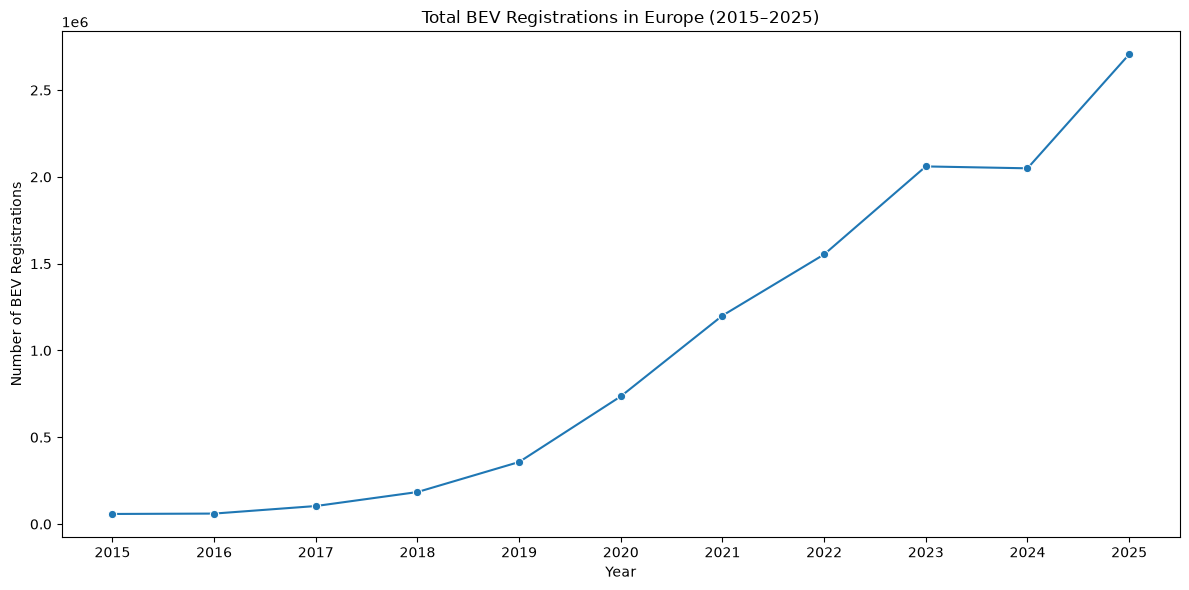

In [11]:
# Group the data by year and calculate total BEV registrations across countries
yearly_registrations = (
    ev_analysis.groupby("year")["bev_registrations"].sum().reset_index()
)

# Create a line chart to visualize the yearly trend
plt.figure(figsize=(12, 6))

sns.lineplot(data=yearly_registrations, x="year", y="bev_registrations", marker="o")

# Add a title and axis labels
plt.title("Total BEV Registrations in Europe (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Number of BEV Registrations")

# Display every year on the x-axis
plt.xticks(yearly_registrations["year"])

# Improve layout and display the chart
plt.tight_layout()
plt.show()

### Key Observations

- BEV registrations began increasing gradually around 2017–2018.
- Growth accelerated significantly between 2019 and 2023.
- Registrations remained almost stable between 2023 and 2024, suggesting a temporary slowdown.
- Registrations increased sharply again in 2025.

Overall, the chart shows a strong upward trend in BEV registrations across the selected European countries.

### Top Countries by BEV Registrations in 2025

We compare countries based on their total BEV registrations in 2025.

This helps identify the countries with the largest number of newly registered battery electric vehicles.

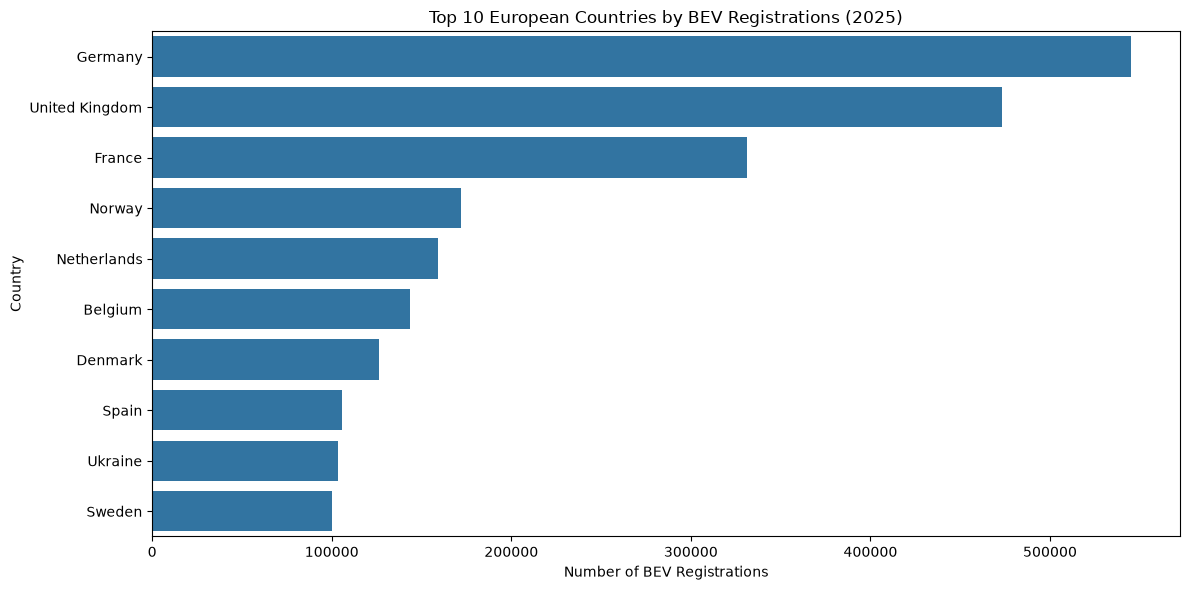

In [12]:
# Select data from 2025 and sort countries by BEV registrations
top_countries_2025 = (
    ev_analysis[ev_analysis["year"] == 2025]
    .sort_values("bev_registrations", ascending=False)
    .head(10)
)

# Create a horizontal bar chart to compare the top 10 countries
plt.figure(figsize=(12, 6))

sns.barplot(data=top_countries_2025, x="bev_registrations", y="country")

# Add chart title and axis labels
plt.title("Top 10 European Countries by BEV Registrations (2025)")
plt.xlabel("Number of BEV Registrations")
plt.ylabel("Country")

# Display the chart
plt.tight_layout()
plt.show()

### Top Countries by BEV Registrations per 1,000 People

Absolute registration numbers tend to favor countries with larger populations.

To make the comparison fairer, we use BEV registrations per 1,000 people. This allows us to compare countries of different sizes.

This metric represents new BEV registrations relative to population, not the total number of electric vehicles already on the road.

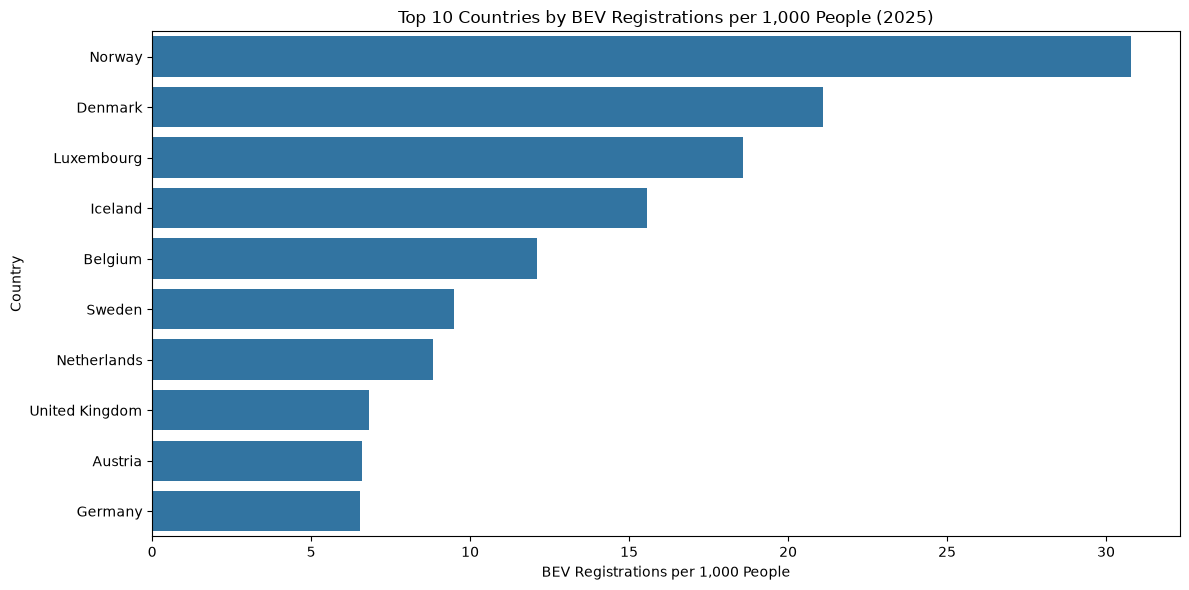

In [13]:
# Select countries with available population-adjusted data for 2025
top_countries_per_capita = (
    ev_analysis[ev_analysis["year"] == 2025]
    .dropna(subset=["bev_registrations_per_1000_people"])
    .sort_values("bev_registrations_per_1000_people", ascending=False)
    .head(10)
)

# Create a horizontal bar chart to compare registrations relative to population
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries_per_capita, x="bev_registrations_per_1000_people", y="country"
)

# Add title and axis labels
plt.title("Top 10 Countries by BEV Registrations per 1,000 People (2025)")
plt.xlabel("BEV Registrations per 1,000 People")
plt.ylabel("Country")

# Display the chart
plt.tight_layout()
plt.show()

### Key Observations

- Norway ranks first in BEV registrations per 1,000 people in 2025.
- Denmark and Luxembourg also perform strongly relative to population.
- Germany ranks much lower in this metric despite leading in total registrations.
- This highlights the importance of using population-adjusted metrics when comparing countries of different sizes.

Norway's EV adoption began accelerating much earlier than in many other European countries, supported by long-term incentives and charging infrastructure.

### Comparing EV Adoption Trends Across Countries

We compare BEV registrations per 1,000 people over time for selected European countries.

This allows us to investigate how adoption has evolved in different markets while accounting for population size.

We selected Norway, Denmark, Germany, France, the United Kingdom and the Netherlands to compare countries with different adoption levels.

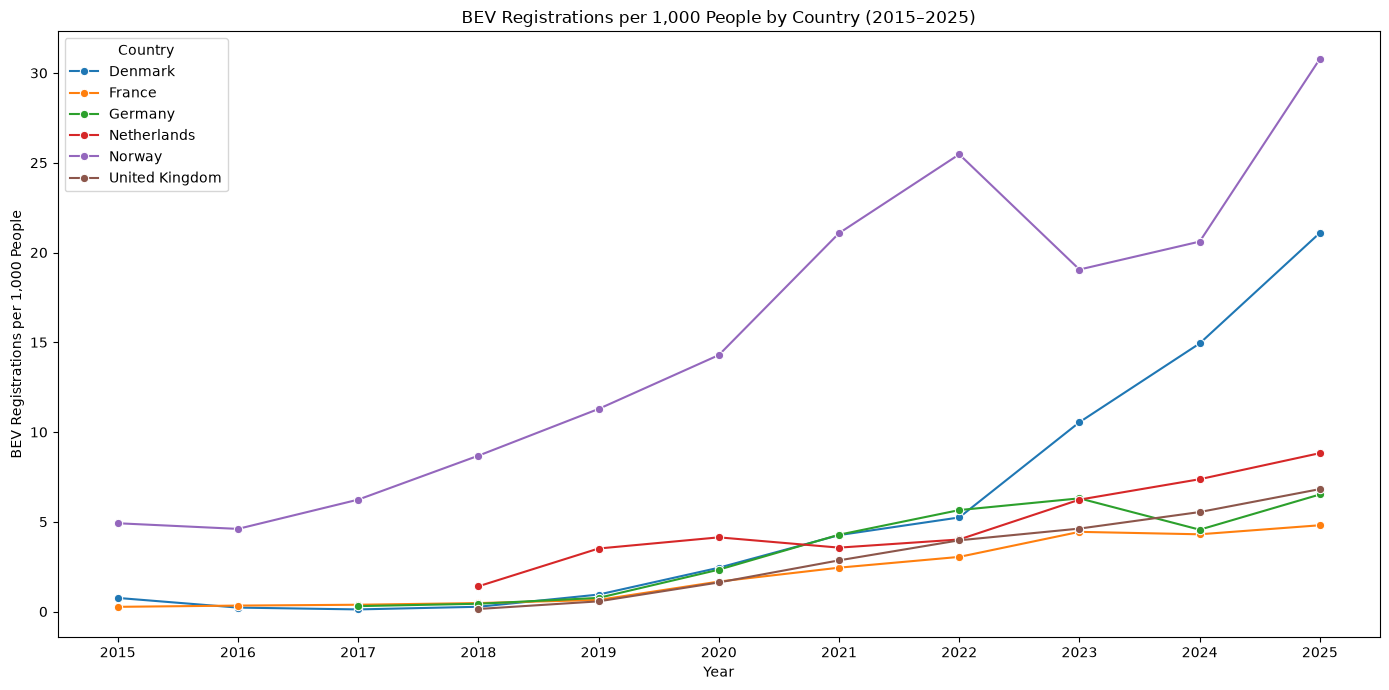

In [14]:
# Define the countries we want to compare
selected_countries = [
    "Norway",
    "Denmark",
    "Germany",
    "France",
    "United Kingdom",
    "Netherlands",
]

# Filter the dataset to include only the selected countries
country_trends = ev_analysis[ev_analysis["country"].isin(selected_countries)].copy()

# Create a line chart showing BEV registrations per 1,000 people over time
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=country_trends,
    x="year",
    y="bev_registrations_per_1000_people",
    hue="country",
    marker="o",
)

# Add chart title and axis labels
plt.title("BEV Registrations per 1,000 People by Country (2015–2025)")
plt.xlabel("Year")
plt.ylabel("BEV Registrations per 1,000 People")

# Display all years on the x-axis
plt.xticks(range(2015, 2026))

# Add a legend and improve the layout
plt.legend(title="Country")
plt.tight_layout()
plt.show()

### Key Observations

- Norway had the highest BEV registrations per 1,000 people throughout the observed period. Registrations increased substantially until 2022, declined in 2023, and rose sharply again in 2025.
- Denmark experienced strong growth, particularly from 2022 onwards.
- Germany showed strong growth until 2023, followed by a decline in 2024 and a recovery in 2025.
- The Netherlands, France and the United Kingdom experienced more gradual growth compared with Norway and Denmark.

Overall, the selected countries show different adoption patterns.
Norway and Denmark stand out for their high population-adjusted registration levels, while Germany experienced substantial growth in absolute registrations.

## Charging Infrastructure and EV Adoption

### Relationship Between Charging Points and BEV Registrations

Charging infrastructure may influence EV adoption by making electric vehicles more convenient to use.

We investigate whether countries with more charging points tend to have higher BEV registrations per 1,000 people.

Since charging infrastructure data is only available for certain years and countries, this analysis uses observations with available data.

In [15]:
# Keep rows where both charging infrastructure and BEV registration
# rates are available
charging_analysis = ev_analysis.dropna(
    subset=["charging_points", "bev_registrations_per_1000_people"]
).copy()

# Display the number of observations available for this analysis
print("Observations:", charging_analysis.shape[0])
print("Countries:", charging_analysis["country"].nunique())
print("Years:", charging_analysis["year"].min(), "-", charging_analysis["year"].max())

Observations: 118
Countries: 30
Years: 2019 - 2025


### Visualizing the Relationship

We use a scatter plot to explore the relationship between the number of charging points and BEV registrations per 1,000 people.

Each point represents one country in one year.

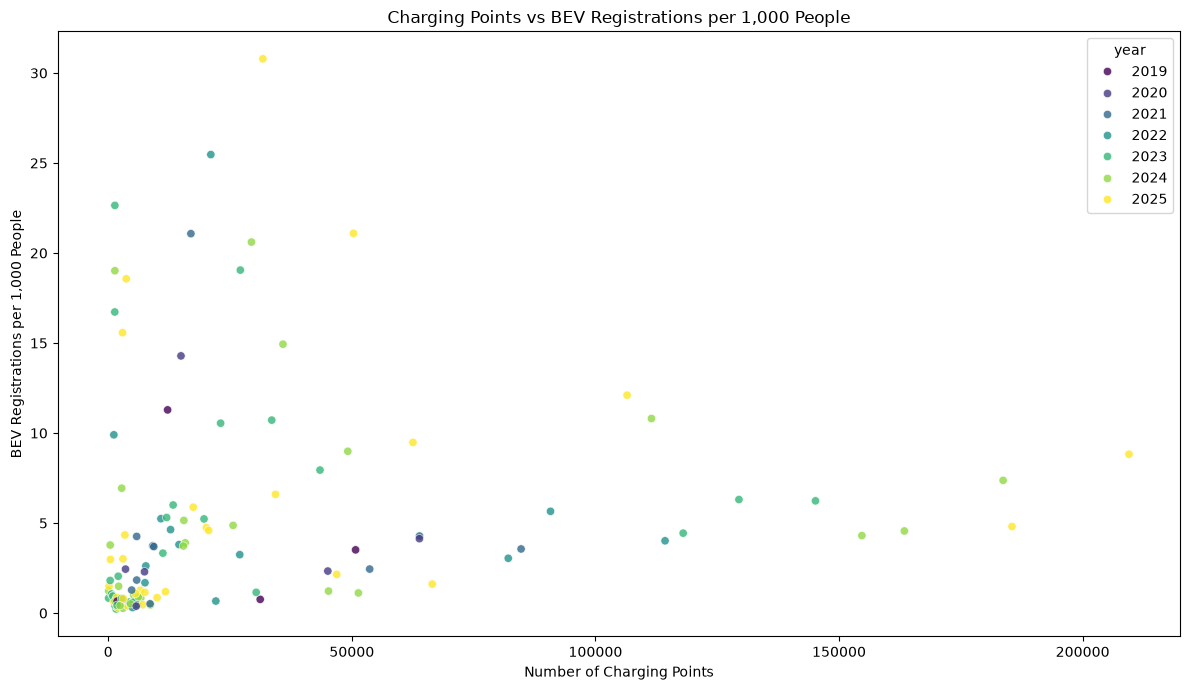

In [16]:
# Create a scatter plot to compare charging infrastructure and BEV registrations
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=charging_analysis,
    x="charging_points",
    y="bev_registrations_per_1000_people",
    hue="year",
    palette="viridis",
    alpha=0.8,
)

# Add chart title and axis labels
plt.title("Charging Points vs BEV Registrations per 1,000 People")
plt.xlabel("Number of Charging Points")
plt.ylabel("BEV Registrations per 1,000 People")

# Improve layout and display the chart
plt.tight_layout()
plt.show()

### Population-Adjusted Charging Infrastructure

Countries with larger populations generally need more charging points.

To make comparisons fairer, we calculate charging points per 100,000 people. This allows us to compare charging infrastructure between countries of different sizes.

In [17]:
# Calculate charging points per 100,000 people
charging_analysis["charging_points_per_100k_people"] = (
    charging_analysis["charging_points"] / charging_analysis["population"] * 100000
)

# Display the new metric to check the calculation
charging_analysis[
    [
        "country",
        "year",
        "charging_points",
        "population",
        "charging_points_per_100k_people",
        "bev_registrations_per_1000_people",
    ]
].head()

,country,year,charging_points,population,charging_points_per_100k_people,bev_registrations_per_1000_people
11,Austria,2021,9143.0,8932664.0,102.354684,3.735280
12,Austria,2022,14526.0,8978929.0,161.778760,3.805020
13,Austria,2023,19663.0,9104772.0,215.963673,5.230334
14,Austria,2024,25632.0,9158750.0,279.863518,4.872062
15,Austria,2025,34333.0,9197213.0,373.297868,6.594498


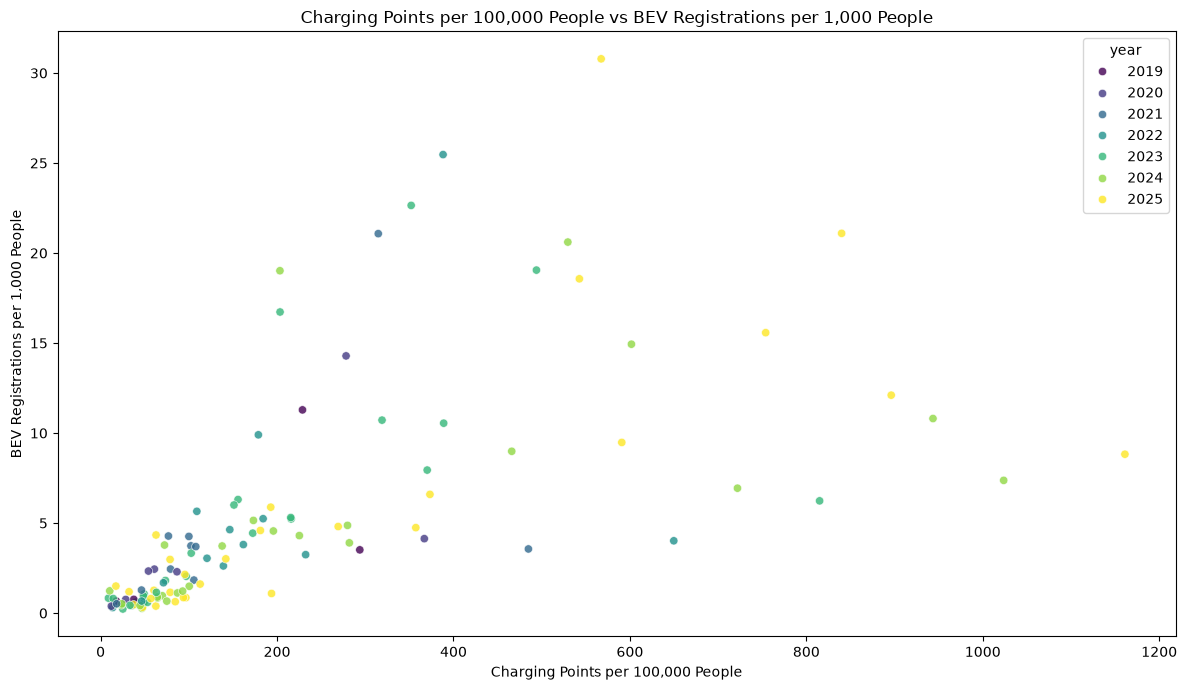

In [ ]:
# Compare charging infrastructure availability with BEV registrations,
# using population-adjusted metrics
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=charging_analysis,
    x="charging_points_per_100k_people",
    y="bev_registrations_per_1000_people",
    hue="year",
    palette="viridis",
    alpha=0.8,
)

# Add chart title and axis labels
plt.title("Charging Points per 100,000 People vs BEV Registrations per 1,000 People")
plt.xlabel("Charging Points per 100,000 People")
plt.ylabel("BEV Registrations per 1,000 People")

# Improve layout and display the chart
plt.tight_layout()
plt.show()

### Correlation Between Charging Infrastructure and EV Registrations

We calculate the Pearson correlation coefficient to measure the linear relationship between charging points per 100,000 people and BEV registrations per 1,000 people.

Correlation indicates association, but it does not prove causation.

In [ ]:
# Calculate the Pearson correlation between the two population-adjusted metrics
charging_correlation = (
    charging_analysis[
        ["charging_points_per_100k_people", "bev_registrations_per_1000_people"]
    ]
    .corr()
    .iloc[0, 1]
)

# Display the correlation coefficient
print("Pearson correlation:", round(charging_correlation, 3))

Pearson correlation: 0.624


### Key Findings: Charging Infrastructure

- Absolute charging point numbers are difficult to compare because countries have different population sizes.
- Charging points per 100,000 people were calculated to account for differences in population size.
- The Pearson correlation between charging points per 100,000 people and BEV registrations per 1,000 people was 0.624.
- This indicates a moderately strong positive linear relationship.
- Countries with more charging infrastructure relative to population tend to have higher BEV registration rates.

However, correlation does not imply causation. Charging infrastructure may support EV adoption, while increasing EV adoption may also encourage the expansion of charging infrastructure.

## GDP per Capita and EV Adoption

This section investigates the relationship between GDP per capita and BEV registrations relative to population.

GDP per capita is used as an indicator of economic prosperity.
The analysis explores whether countries with higher income levels tend to have higher BEV registration rates.

In [ ]:
# Keep observations where GDP per capita and BEV registrations per 1,000 people are available
gdp_analysis = ev_analysis.dropna(
    subset=["gdp_per_capita", "bev_registrations_per_1000_people"]
).copy()

# Display the number of observations and countries included
print("Observations:", gdp_analysis.shape[0])
print("Countries:", gdp_analysis["country"].nunique())
print("Years:", gdp_analysis["year"].min(), "-", gdp_analysis["year"].max())

Observations: 210
Countries: 31
Years: 2015 - 2025


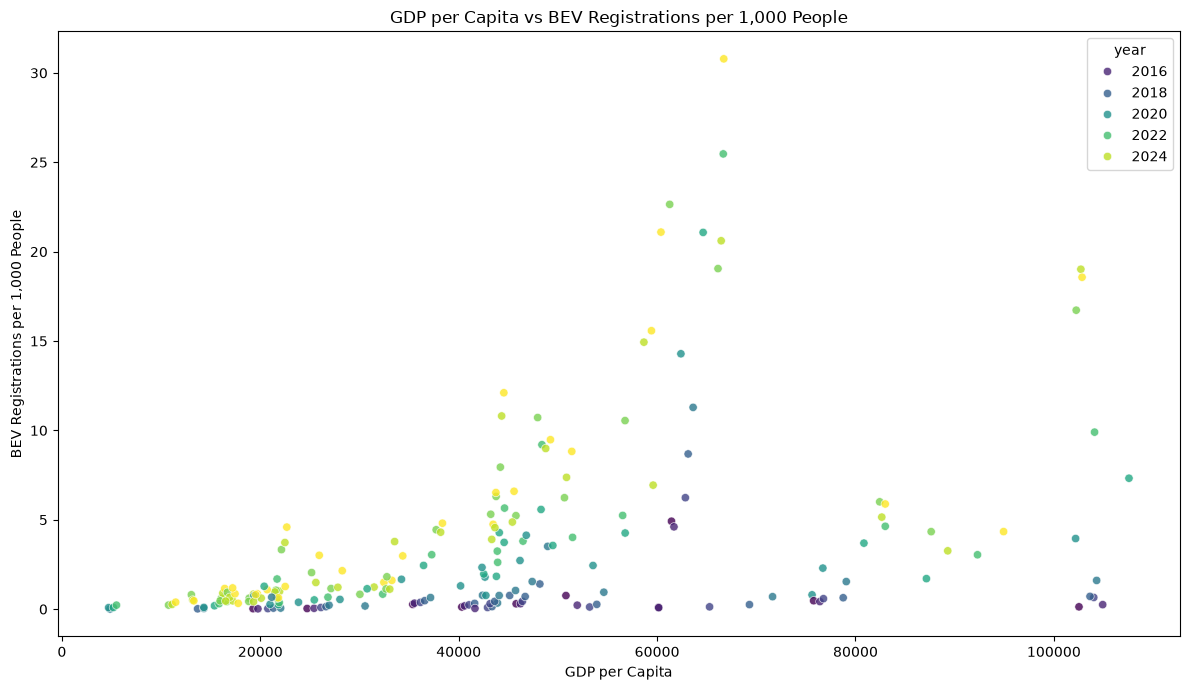

In [ ]:
# Compare GDP per capita with population-adjusted BEV registrations
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=gdp_analysis,
    x="gdp_per_capita",
    y="bev_registrations_per_1000_people",
    hue="year",
    palette="viridis",
    alpha=0.8,
)

# Add chart title and axis labels
plt.title("GDP per Capita vs BEV Registrations per 1,000 People")
plt.xlabel("GDP per Capita")
plt.ylabel("BEV Registrations per 1,000 People")

# Improve layout and display the chart
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the Pearson correlation between GDP per capita and BEV registrations
gdp_correlation = (
    gdp_analysis[["gdp_per_capita", "bev_registrations_per_1000_people"]]
    .corr()
    .iloc[0, 1]
)

# Display the correlation coefficient
print("Pearson correlation:", round(gdp_correlation, 3))

Pearson correlation: 0.427


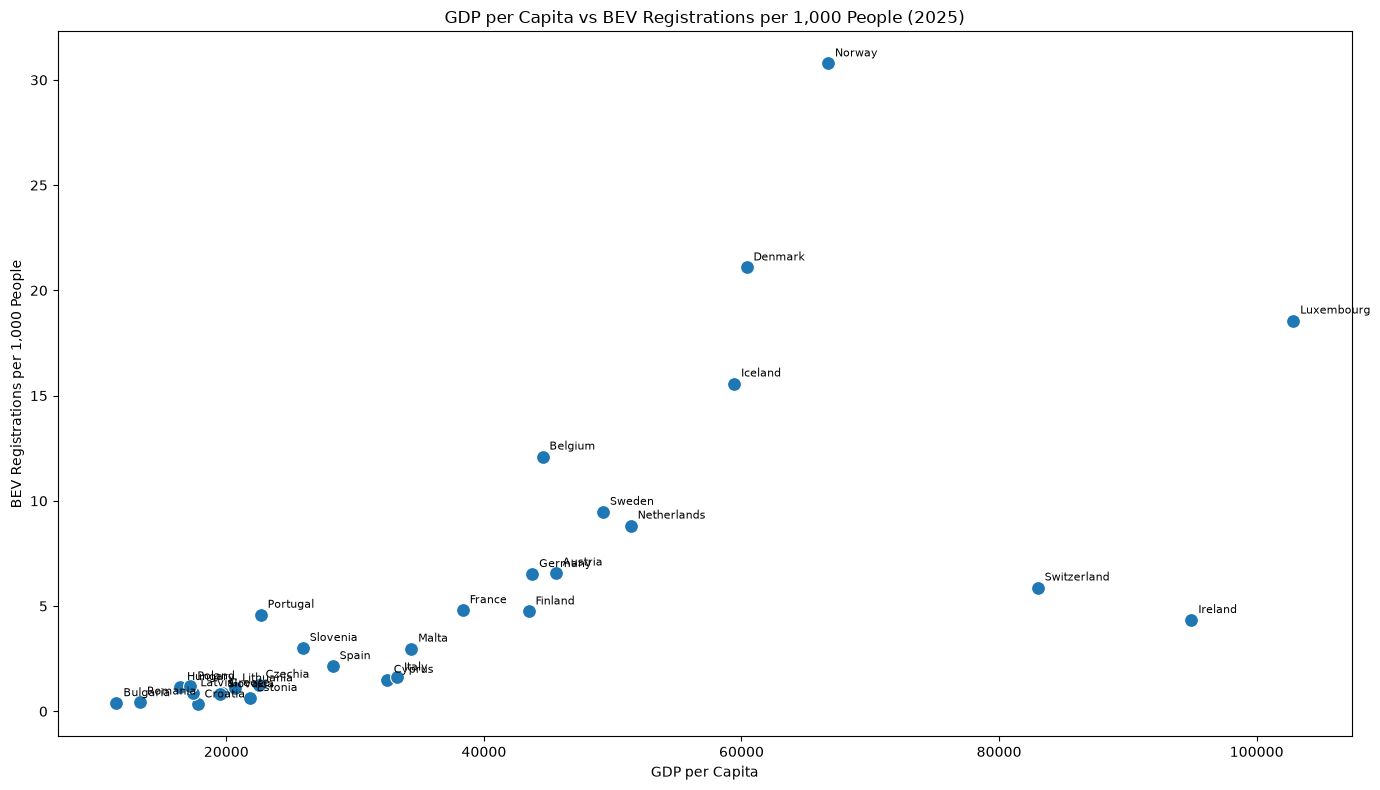

In [ ]:
# Select the latest year with data for GDP per capita and BEV registrations
gdp_2025 = gdp_analysis[gdp_analysis["year"] == 2025].copy()

# Create a scatter plot for the 2025 country comparison
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=gdp_2025, x="gdp_per_capita", y="bev_registrations_per_1000_people", s=100
)

# Add country names beside each point
for _, row in gdp_2025.iterrows():
    plt.annotate(
        row["country"],
        (row["gdp_per_capita"], row["bev_registrations_per_1000_people"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

# Add chart title and axis labels
plt.title("GDP per Capita vs BEV Registrations per 1,000 People (2025)")
plt.xlabel("GDP per Capita")
plt.ylabel("BEV Registrations per 1,000 People")

# Improve layout and display the chart
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the correlation using only 2025 observations
gdp_correlation_2025 = (
    gdp_2025[["gdp_per_capita", "bev_registrations_per_1000_people"]].corr().iloc[0, 1]
)

# Display the correlation coefficient
print("2025 Pearson correlation:", round(gdp_correlation_2025, 3))

2025 Pearson correlation: 0.67


### Key Findings: GDP per Capita

- The Pearson correlation across all available observations from 2015 to 2025 was 0.427, indicating a moderate positive relationship.
- The 2025 country-level comparison showed a stronger positive correlation of 0.670.
- Countries with higher GDP per capita generally tended to have higher BEV registrations per 1,000 people.
- Norway and Denmark showed particularly high registration rates.
- Ireland and Switzerland had relatively high GDP per capita but lower registration rates than some other wealthy countries.

These results suggest that economic prosperity may be associated with BEV adoption. However, GDP per capita alone does not explain differences between countries. Government incentives, charging infrastructure, electricity prices and other factors may also influence adoption.

Correlation does not imply causation.

## Electricity Prices and EV Adoption

This section investigates the relationship between household electricity prices and BEV registrations per 1,000 people.

Electricity prices may influence the cost of charging electric vehicles and could therefore affect the attractiveness of EVs.

In [ ]:
# Keep observations where electricity prices and BEV registration rates are available
electricity_analysis = ev_analysis.dropna(
    subset=["electricity_price", "bev_registrations_per_1000_people"]
).copy()

# Display the number of observations and countries included
print("Observations:", electricity_analysis.shape[0])
print("Countries:", electricity_analysis["country"].nunique())
print(
    "Years:",
    electricity_analysis["year"].min(),
    "-",
    electricity_analysis["year"].max(),
)

Observations: 210
Countries: 32
Years: 2015 - 2025


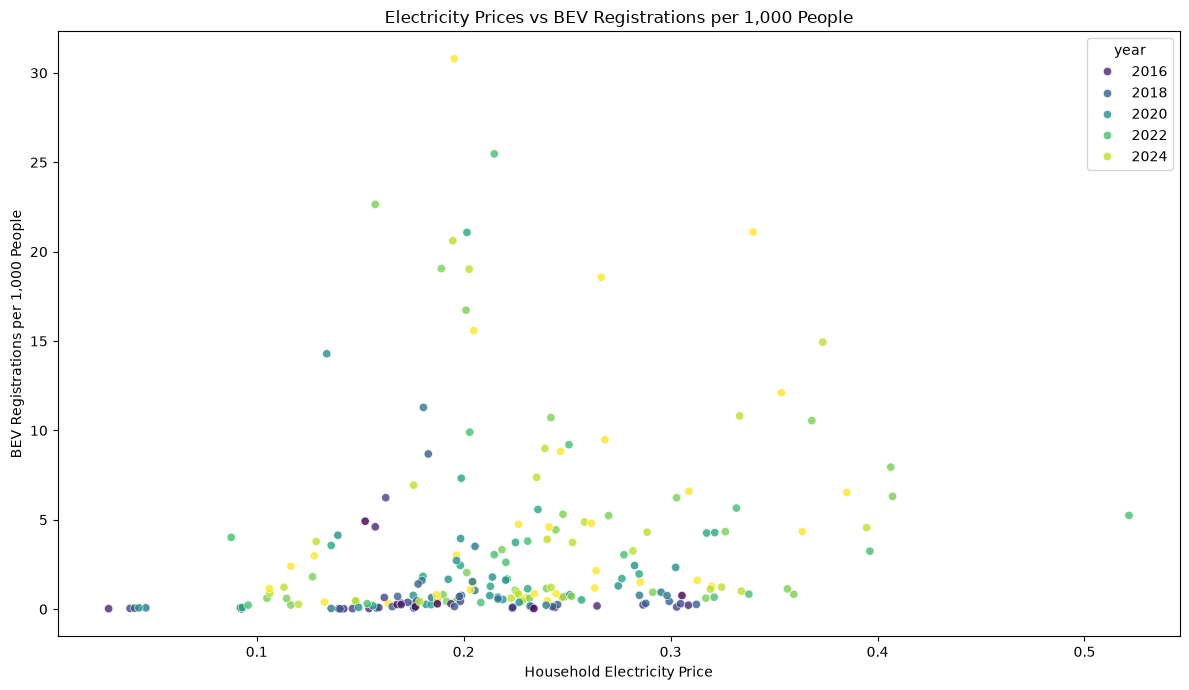

In [26]:
# Compare electricity prices with BEV registrations per 1,000 people
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=electricity_analysis,
    x="electricity_price",
    y="bev_registrations_per_1000_people",
    hue="year",
    palette="viridis",
    alpha=0.8
)

# Add chart title and axis labels
plt.title("Electricity Prices vs BEV Registrations per 1,000 People")
plt.xlabel("Household Electricity Price")
plt.ylabel("BEV Registrations per 1,000 People")

# Improve layout and display the chart
plt.tight_layout()
plt.show()

In [27]:
# Calculate the Pearson correlation between electricity prices and BEV registration rates
electricity_correlation = electricity_analysis[
    [
        "electricity_price",
        "bev_registrations_per_1000_people"
    ]
].corr().iloc[0, 1]

# Display the correlation coefficient
print("Pearson correlation:", round(electricity_correlation, 3))

Pearson correlation: 0.159


### Key Findings: Electricity Prices

- The Pearson correlation across available observations from 2015 to 2025 was 0.159, indicating a very weak positive relationship.
- The scatterplot shows substantial variation in BEV registration rates among countries with similar electricity prices.
- Household electricity prices alone do not appear to explain differences in BEV adoption.

Household electricity prices may not fully represent the cost of charging an EV, as charging costs depend on tariffs, taxes and whether charging takes place at home or at public stations.

The results suggest that electricity prices may be less strongly associated with BEV adoption than GDP per capita or charging infrastructure in this dataset.

Correlation does not imply causation.

## Government Policies and EV Incentives

Economic conditions and charging infrastructure are not the only factors that may influence electric vehicle adoption.

Government policies can encourage consumers to choose electric vehicles by reducing purchase costs and ownership expenses.

Examples include:

- Direct purchase subsidies.
- Reduced vehicle taxes and VAT.
- Lower parking fees or road tolls.
- Financial support for charging infrastructure.

This section compares government support measures in Norway, Switzerland and Spain.

The objective is to investigate whether differences in government policies may provide additional context for the adoption patterns observed in the previous analysis.

### Comparison of Government Policies

| Country | Government support | Main characteristics |
|---|---|---|
| Norway | VAT advantages for BEVs | VAT exemption applies to the first NOK 300,000 of the vehicle price. The amount above this threshold is subject to 25% VAT. |
| Switzerland | Cantonal and local incentives | No direct federal purchase subsidy. Some cantons, municipalities, cities and energy providers offer financial benefits or incentives. |
| Spain | Direct purchase subsidies | The 2026 Auto+ programme provides purchase support for eligible electric vehicles, with maximum grants of €4,500 for private individuals purchasing eligible passenger cars. |

#### Sources

- Norway: [Norwegian Customs – Electric Vehicles](https://www.toll.no/en/goods/motor-vehicles/electric-vehicles/)
- Switzerland: [Federal Office of Energy – Financial Benefits](https://www.bfe.admin.ch/en/financial-benefits-for-efficient-vehicles)
- Spain: [Spanish Government – Auto+ Programme](https://www.lamoncloa.gob.es/serviciosdeprensa/notasprensa/industria-turismo/Paginas/2026/plan-auto-plus-requisitos.aspx)

### Key Observations: Government Policies

- Norway has maintained substantial tax advantages for electric
  vehicles, making BEVs financially attractive compared with
  conventional vehicles.
- Switzerland does not offer a nationwide direct purchase subsidy.
  Instead, financial support is mainly provided at cantonal,
  municipal and local levels.
- Spain has used national purchase-support programmes, including
  MOVES and the newer Auto+ programme introduced in 2026.

These differences provide additional context for the adoption
patterns observed across the three countries.

Norway's long-standing tax advantages are consistent with its
high BEV adoption level, while Switzerland's decentralized
incentive system represents a different approach.

Spain's recent purchase-support measures may support further
market growth.

However, this comparison does not establish a causal relationship
between government incentives and BEV adoption. Other factors,
including income, charging infrastructure, vehicle prices and
consumer preferences, may also influence adoption.